# SocialChoice 01c : Le paradoxe de la non-participation (no-show) — twin C# .NET

> **Twin C# .NET de `GameTheory/SocialChoice/ChoixSocial-01c-Paradoxe-NonParticipation-NoShow-Python.ipynb`** (Python).
> Implémentations **from-scratch** (BCL .NET 9, **0 NuGet** pour les algorithmes ; ScottPlot 5 pour la figure).

**Le critère de participation.** Ajouter à un profil un électeur qui classe le gagnant *en tête* de son bulletin ne doit jamais faire gagner un candidat que cet électeur préfère *moins*. Le **paradoxe de la non-participation** (*no-show paradox*) est l'échec de cette propriété : un électeur **parfaitement sincère** est strictement mieux servi en **s'abstenant** qu'en votant.

**Plan :**
1. Le critère de participation + le prédicat `EstNoShow` ;
2. Les deux règles from-scratch (Borda, IRV) ;
3. **Borda est immunisé** — recherche exhaustive (~2,8 M de profils, zéro no-show) ;
4. **IRV exhibite le no-show** — un profil à 5 votants déroulé à la main + figure ;
5. Moulin (1988) + les distinctions ;
6. Trois exercices (stubs compilables, `// TODO etudiant`).

**★ Leçon de parité : déterministe = reproductible.** Le jumeau Python est **déterministe** (aucune RNG) : les deux twins rejouent exactement les mêmes profils et la parité se **vérifie par assertion** sur des sorties reproductibles à l'identique — contrairement à un jumeau stochastique dont les RNG Python et C# divergeraient.

*Carnet issu de l'EPIC #28578.*

## 0. Configuration

**Pourquoi trois setters de culture ?** La cellule suivante n'assigne pas un mais trois propriétés (`CurrentCulture`, `DefaultThreadCurrentCulture`, `DefaultThreadCurrentUICulture`) à `InvariantCulture` : en .NET Interactive, `CurrentCulture` seul **ne persiste pas d'une cellule à l'autre** (chaque cellule peut s'exécuter sur un thread distinct du pool). Sans ces trois setters, un `string.Format` ou un tri par score pourrait se comporter différemment selon la culture de la machine (séparateurs, ordres de tri) et casser la reproductibilité cross-machine. La sortie `Configuration OK` est le seul output attendu : elle prouve que la cellule a tourné dans le bon environnement.

In [1]:
// SocialChoice 01c : Paradoxe de la non-participation (no-show) -- twin C# de 01c
// Prong B (#3801) : implementations from-scratch (BCL .NET 9, 0 NuGet).
// Lecon c.94 : les 3 setters de culture sont requis (CurrentCulture seul ne
// persiste pas cross-cell, threads du pool distincts).
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;

Console.WriteLine("Configuration OK : SocialChoice 01c - No-show (twin C# .NET)");


The below script needs to be able to find the current output cell; this is an easy method to get it.

Configuration OK : SocialChoice 01c - No-show (twin C# .NET)


***

## 1. Le critère de participation

Formalisons l'intuition. Soit une règle de vote $f$ qui, à un **profil** de préférences (la liste des bulletins), associe un **gagnant**. Le **critère de participation** dit :

> Ajouter à un profil un électeur qui classe le gagnant *en tête* de son bulletin ne doit jamais changer le gagnant en faveur d'un candidat que cet électeur préfère *moins*.

Autrement dit, si $v$ est un électeur dont le premier choix est $t$, la règle satisfait le critère si :

$$
f(\text{profil}) = t \;\;\Longrightarrow\;\; f(\text{profil} \cup \{v\}) = t .
$$

Le **paradoxe de la non-participation** est l'échec de cette propriété : il existe un profil et un électeur $v$ tels que

$$
f(\text{autres}) = t \quad\text{mais}\quad f(\text{autres} \cup \{v\}) \neq t ,
$$

où $t$ est le premier choix de $v$. $v$ gagne *davantage* en restant chez lui : **son vote sincère lui est préjudiciable**.

Deux précisions posent le cadre :

- **Ce n'est pas la manipulation.** La manipulation (carnet 05, Gibbard-Satterthwaite) est un électeur qui *déforme* son bulletin pour gagner. Le no-show est plus sournois : l'électeur est **parfaitement sincère**, et c'est précisément sa sincérité qui le pénalise. Il n'y a rien à corriger dans son bulletin — il y a à ne pas voter.
- **C'est une propriété de la règle, pas d'un profil.** Un no-show sur un profil donné montre que la *règle* est vulnérable : il existe des électeurs sincères qui s'abstiendront stratégiquement, ce qui biaise le scrutin au profit des abstentionnistes.

Le prédicat `EstNoShow` ci-dessous automatise exactement cette définition, pour n'importe quelle règle :

In [2]:
// === Section 1 : Deux regles de vote, from scratch (BCL, 0 NuGet) ===
// Un profil = liste de classements : chaque bulletin est un tableau
// d'alternatives, du plus preferé au moins preferé.
//
// Borda(profil)  -> gagnant de Borda (points decroissants m-1, ..., 0)
// Irv(profil)    -> gagnant au vote instantané (elimination + transfert)
//
// Un departage lexicographique (alphabetique) est fixe une fois pour toutes :
// sans departage, une regle a egalite n'est pas une regle complete.

static string Borda(List<string[]> profil)
{
    int m = profil[0].Length;
    var points = new Dictionary<string, int>();
    foreach (var c in profil[0]) points[c] = 0;
    foreach (var rang in profil)
        for (int pos = 0; pos < rang.Length; pos++)
            points[rang[pos]] += (m - 1 - pos);
    int meilleur = points.Values.Max();
    return points.Where(kv => kv.Value == meilleur)
                 .Select(kv => kv.Key)
                 .OrderBy(k => k, StringComparer.Ordinal)
                 .First();
}

static string Irv(List<string[]> profil, bool trace = false)
{
    string[] alts = (string[])profil[0].Clone();
    var bulletins = profil.Select(b => new List<string>(b)).ToList();
    int tour = 0;
    var elimines = new List<string>();
    while (true)
    {
        tour += 1;
        bulletins = bulletins.Where(b => b.Count > 0).ToList();
        if (bulletins.Count == 0)
            return null;
        var compte = new Dictionary<string, int>();
        foreach (var b in bulletins)
            compte[b[0]] = compte.TryGetValue(b[0], out int n) ? n + 1 : 1;
        int actifs = compte.Values.Sum();
        if (trace)
        {
            var parts = new List<string>();
            foreach (var c in alts)
                parts.Add(elimines.Contains(c)
                    ? c + "=— (éliminé)"
                    : c + "=" + (compte.TryGetValue(c, out int vv) ? vv : 0));
            Console.WriteLine("   tour " + tour + ": " + string.Join("  ", parts) + "    (actifs=" + actifs + ")");
        }
        foreach (var kv in compte)
        {
            if (kv.Value * 2 > actifs)
            {
                if (trace)
                    Console.WriteLine("      -> " + kv.Key + " a la majorite (" + kv.Value + "/" + actifs + ")");
                return kv.Key;
            }
        }
        var presents = alts.Where(c => compte.TryGetValue(c, out int pc) && pc > 0).ToList();
        if (presents.Count == 1)
            return presents[0];
        var plus_bas = presents.OrderBy(c => compte[c]).ThenBy(c => c, StringComparer.Ordinal).First();
        if (trace)
            Console.WriteLine("      elimine " + plus_bas + " (" + compte[plus_bas] + " voix)");
        elimines.Add(plus_bas);
        var transferts = new Dictionary<string, int>();
        foreach (var b in bulletins)
        {
            if (b.Count > 0 && b[0] == plus_bas)
            {
                var restants = b.Skip(1).Where(x => !elimines.Contains(x)).ToList();
                b.Clear();
                b.AddRange(restants);
                if (restants.Count > 0)
                    transferts[restants[0]] = transferts.TryGetValue(restants[0], out int tn) ? tn + 1 : 1;
            }
        }
        if (trace && transferts.Count > 0)
        {
            var tp = transferts.Select(kv => plus_bas + " -> " + kv.Key + " (" + kv.Value + " bulletin" + (kv.Value > 1 ? "s" : "") + ")");
            Console.WriteLine("      transfert : " + string.Join("  ", tp));
        }
    }
}

static bool EstNoShow(Func<List<string[]>, string> regle, string[] votant, List<string[]> autres)
{
    // True si voter sincèrement nuit a `votant` : sans lui son 1er choix gagne,
    // avec lui ce n'est plus le cas.
    string favori = votant[0];
    string sans = regle(autres);
    var avec = new List<string[]>(autres);
    avec.Insert(0, votant);
    string avecG = regle(avec);
    return sans == favori && avecG != favori;
}

Console.WriteLine("Règles définies : Borda, Irv, EstNoShow");


Règles définies : Borda, Irv, EstNoShow


***

## 2. Borda est immunisé — un argument, puis une vérification exhaustive

Commençons par la famille qui **respecte** le critère : les méthodes **positionnelles**, et Borda en tête.

**L'argument (monotonie).** À Borda, un électeur qui classe $t$ **en tête** de son bulletin verse à $t$ le **maximum** de points disponible, et à aucun autre candidat une somme qui « rattraperait » $t$. Son bulletin **n'augmente que la colonne de $t$** (relativement aux autres). Il est donc **structurellement impossible** que l'ajout d'un tel bulletin fasse passer un concurrent devant $t$ au moment où $t$ gagnait : on n'ajoute des points qu'au gagnant.

C'est un argument, pas une preuve : le fait de le *vérifier* sur l'espace entier des petits profils en fait un résultat solide.

In [3]:
// === Section 2 : Recherche exhaustive -- Borda exhibe-t-il le no-show ? ===
// Espace : 4 alternatives, les 24 classements possibles, 4 puis 5 autres
// votants (TOUTES les multisets). Pour chaque electeur v on teste le
// critere : sans lui, son 1er choix gagne-t-il ? Avec lui, cesse-t-il de
// gagner ?  Le comptage des vecteurs de score (pre-calculs) rend le balayage
// rapide (~3 millions de profils en quelques secondes).

static string GagnantBorda(IEnumerable<int[]> vecs, string[] alts)
{
    var tot = new int[4];
    foreach (var sv in vecs)
        for (int i = 0; i < 4; i++) tot[i] += sv[i];
    int best = tot.Max();
    return Enumerable.Range(0, 4)
        .Where(i => tot[i] == best)
        .Select(i => alts[i])
        .OrderBy(x => x, StringComparer.Ordinal)
        .First();
}

static List<int[]> CombinationsWithReplacement(int n, int k)
{
    var result = new List<int[]>();
    var idx = new int[k];
    void Recur(int depth, int start)
    {
        if (depth == k) { result.Add((int[])idx.Clone()); return; }
        for (int i = start; i < n; i++) { idx[depth] = i; Recur(depth + 1, i); }
    }
    Recur(0, 0);
    return result;
}

string[] ALTS = { "A", "B", "C", "D" };
var RANGS = new List<string[]>();
{
    var perm = new int[] { 0, 1, 2, 3 };
    void Gen(int kk)
    {
        if (kk == perm.Length) { RANGS.Add(perm.Select(i => ALTS[i]).ToArray()); return; }
        for (int i = kk; i < perm.Length; i++)
        {
            (perm[kk], perm[i]) = (perm[i], perm[kk]);
            Gen(kk + 1);
            (perm[kk], perm[i]) = (perm[i], perm[kk]);
        }
    }
    Gen(0);
}
int[] PTS = { 3, 2, 1, 0 };
var VEC = new Dictionary<string, int[]>();
foreach (var r in RANGS)
{
    var key = string.Join("", r);
    var v = new int[4];
    for (int pos = 0; pos < r.Length; pos++)
        v[Array.IndexOf(ALTS, r[pos])] = PTS[pos];
    VEC[key] = v;
}

long total = 0;
long no_show = 0;
int nRangs = RANGS.Count;
foreach (int n_autres in new[] { 4, 5 })
{
    var combos = CombinationsWithReplacement(nRangs, n_autres);
    foreach (var v in RANGS)
    {
        string fav = v[0];
        var fv = VEC[string.Join("", v)];
        foreach (var combo in combos)
        {
            total += 1;
            var av = new List<int[]>();
            foreach (var ci in combo) av.Add(VEC[string.Join("", RANGS[ci])]);
            if (GagnantBorda(av, ALTS) == fav)
            {
                av.Add(fv);
                if (GagnantBorda(av, ALTS) != fav) no_show += 1;
            }
        }
    }
}

Console.WriteLine("Profils testés          : " + total.ToString("#,##0", CultureInfo.InvariantCulture));
Console.WriteLine("No-show de Borda trouvés: " + no_show);


Profils testés          : 2,779,920


No-show de Borda trouvés: 0


<null>

**Lecture.** Sur ~2,8 millions de profils, **zéro** no-show de Borda. L'argument de monotonie est confirmé : un bulletin sincère qui classe le vainqueur en tête ne peut que l'aider. Le zéro est **borné par l'espace parcouru** (4 alternatives, ≤ 5 autres votants) — comme toute mesure par énumération, il n'est pas un théorème universel, mais il rend l'immunité *tangible* et cohérente avec l'intuition.

> **À retenir** : l'immunité de Borda n'est pas un accident de notre échantillon, c'est une **conséquence de la structure** des scores — voter son favori en tête verse des points *au* favori, jamais *contre* lui.

***

## 3. IRV exhibite le no-show — un profil de 5 votants, déroulé à la main

Passons à la famille qui **viole** le critère : les règles à **élimination**, représentées ici par le **vote instantané** (IRV). Contrairement à Borda, IRV ne fait pas la somme de scores : il **élimine** tour après tour le candidat le moins présent en tête, en transférant ses bulletins. C'est cette dynamique d'élimination — et non l'agrégation de points — qui ouvre la porte au piège.

Voici un profil minimal, trouvé par recherche et **vérifié ci-dessous**. Trois candidats $A, B, C$ ; l'électeur $v$ (dont le bulletin sincère est $C \succ A \succ B$) et 4 autres votants :

| Bulletins | Classement |
|---|---|
| $v$ (l'électeur à l'étude) | $C \succ A \succ B$ |
| 2 votants | $A \succ C \succ B$ |
| 2 votants | $B \succ A \succ C$ |

La question : **$v$ a-t-il intérêt à voter ?** Son premier choix est $C$.

In [4]:
// === Section 3 : Le profil de la section 3 -- IRV exhibite le no-show ===
var v = new[] { "C", "A", "B" };
var autres = new List<string[]>
{
    new[] { "A", "C", "B" },
    new[] { "A", "C", "B" },
    new[] { "B", "A", "C" },
    new[] { "B", "A", "C" }
};

Console.WriteLine("== SANS v (4 votants) ==");
string sans = Irv(autres, true);
Console.WriteLine("   GAGNANT sans v : " + sans + "\n");

Console.WriteLine("== AVEC v (5 votants), v = C > A > B ==");
var avecProfil = new List<string[]>(autres);
avecProfil.Insert(0, v);
string avec = Irv(avecProfil, true);
Console.WriteLine("   GAGNANT avec v : " + avec + "\n");

Console.WriteLine("v préfère C.  Sans voter il obtient " + sans +
      " - en votant il obtient " + avec + ".");
Console.WriteLine("\nNO-SHOW PARADOX : " + (EstNoShow(p => Irv(p, false), v, autres) ? "CONFIRMÉ" : "non"));


== SANS v (4 votants) ==


   tour 1: A=2  C=0  B=2    (actifs=4)


      elimine A (2 voix)


      transfert : A -> C (2 bulletins)


   tour 2: A=— (éliminé)  C=2  B=2    (actifs=4)


      elimine B (2 voix)


... (9 outputs left out)

      -> A a la majorite (3/5)


   GAGNANT avec v : A



v préfère C.  Sans voter il obtient C - en votant il obtient A.



NO-SHOW PARADOX : CONFIRMÉ


**Le mécanisme, précisément.** La différence tient à la **présence en tête** de $C$ :

- **Sans $v$**, $C$ n'a **aucun** bulletin en tête. Un candidat sans bulletin n'est pas éliminable (il n'a rien à transférer) : il sert au contraire de **cible**. À mesure que $A$ puis $B$ tombent, leurs bulletins ($A \succ C \succ B$ et $B \succ A \succ C$) se redirigent vers $C$, qui cumule la majorité et **gagne** — c'est le premier choix de $v$.
- **Avec $v$**, son bulletin $C \succ A \succ B$ donne à $C$ **une** voix en tête. $C$ devient alors **le moins présent** ($1 < 2$) : il est **éliminé** au premier tour, et l'unique bulletin qui porte $C$ — celui de $v$ — est transféré vers $A$, le 2e choix de $v$. Ce transfert supplémentaire porte $A$ à la majorité.

Le piège est donc **dynamique**, et c'est là toute la différence avec Borda :

- à **Borda**, le vote de $v$ *ajoute des points à $C$* — il ne peut qu'aider $C$ ;
- à **IRV**, le vote de $v$ *change l'ordre des éliminations* : $C$ passe de « hors-jeu, donc gagnant par transfert » à « éliminé, son bulletin part vers $A$ ». Le même bulletin sincère **déclenche** le transfert qui tue son propre favori.

> C'est le **« center squeeze »** des règles à élimination : l'arrivée d'un vote « central » rebascule l'ordre des éliminations et fait basculer l'issue contre le vote qui l'a provoqué.

> **Comment lire la trace.** Une ligne `élimine X` n'est pas une disparition : les bulletins de $X$ sont **transférés** au premier choix qui lui reste — la ligne `transfert : X -> Y` le dit à chaque tour. C'est exactement pour cela qu'un candidat éliminé peut réapparaître au tour suivant ($B$ éliminé, ses bulletins partent vers $A$, et $A$ réapparaît en tête) : il n'a pas été réadmis, ce sont des bulletins qui lui reviennent par transfert. Un candidat éliminé s'affiche `— (éliminé)` aux tours suivants : son score n'est plus compté en tête de bulletin.

Installed Packages ScottPlot, 5.0.55

Figure generee : 2 scenarios (sans / avec v), barre rouge = candidat elimine au tour 1.


   SANS v : elimine = A   |   AVEC v : elimine = C



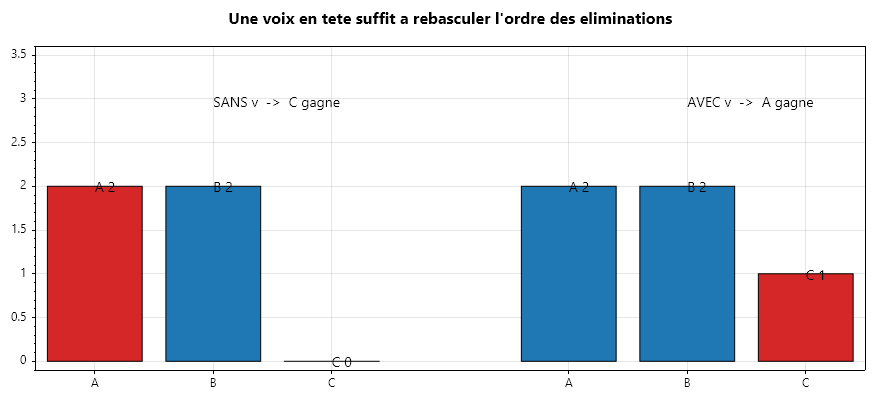


warning CS1701: Assuming assembly reference 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' used by 'Microsoft.DotNet.Interactive' matches identity 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' of 'Microsoft.AspNetCore.Html.Abstractions', you may need to supply runtime policy



In [5]:
// === Section 3 (figure) : l'effet du bulletin de v sur l'ordre des eliminations (tour 1) ===
// Barres = bulletins en 1re place de chaque candidat au tour 1. Deux scenarios
// cote a cote : SANS v (gauche) puis AVEC v (droite). Le candidat elimine au
// tour 1 (le moins present en tete, egalites tranchees par le nom) est en ROUGE,
// les autres en bleu. Sans v, C n'a pas de bulletin : A est elimine, C reste la
// cible de transfert. Avec v, C a une voix : C est elimine, son bulletin part vers A.
#r "nuget: ScottPlot, 5.0.55"
using ScottPlot;
using Microsoft.DotNet.Interactive;

static Dictionary<string, int> CompterTete(List<string[]> profil)
{
    var c = new Dictionary<string, int>();
    foreach (var b in profil)
        if (b.Length > 0)
            c[b[0]] = c.TryGetValue(b[0], out int nn) ? nn + 1 : 1;
    return c;
}
static double Ct(Dictionary<string, int> d, string k) => d.TryGetValue(k, out int nn) ? nn : 0;

// Le candidat elimine au tour 1 dans un scenario : le moins present en tete
// (egalites tranchees par le nom) -- miroir de la regle Irv ci-dessus.
static int IndiceElimine(double[] ys, string[] alts)
{
    int eIdx = -1; int best = int.MaxValue; string bestName = "";
    for (int i = 0; i < alts.Length; i++)
        if (ys[i] > 0)
        {
            int cc = (int)ys[i];
            if (cc < best || (cc == best && alts[i].CompareTo(bestName) < 0)) { best = cc; bestName = alts[i]; eIdx = i; }
        }
    return eIdx;
}

string[] altsFig = { "A", "B", "C" };
var sansFig = CompterTete(autres);
var avecFig = CompterTete(avecProfil);

double[] xs = { 0, 1, 2, 4, 5, 6 };
double[] yS = { Ct(sansFig, "A"), Ct(sansFig, "B"), Ct(sansFig, "C") };
double[] yA = { Ct(avecFig, "A"), Ct(avecFig, "B"), Ct(avecFig, "C") };
double[] ys = { yS[0], yS[1], yS[2], yA[0], yA[1], yA[2] };
int eS = IndiceElimine(yS, altsFig);
int eA = IndiceElimine(yA, altsFig);

var pltFig = new ScottPlot.Plot();
var barsFig = pltFig.Add.Bars(xs, ys);
for (int i = 0; i < 3; i++)
    barsFig.Bars[i].FillColor = ScottPlot.Color.FromHex(i == eS ? "#d62728" : "#1f77b4");
for (int i = 0; i < 3; i++)
    barsFig.Bars[3 + i].FillColor = ScottPlot.Color.FromHex(i == eA ? "#d62728" : "#1f77b4");
// Etiquettes : nom du candidat + nombre de bulletins au-dessus de chaque barre.
for (int i = 0; i < 3; i++)
{
    pltFig.Add.Text(altsFig[i] + " " + (int)yS[i], xs[i], yS[i] + 0.08);
    pltFig.Add.Text(altsFig[i] + " " + (int)yA[i], xs[3 + i], yA[i] + 0.08);
}
pltFig.Add.Text("SANS v  ->  C gagne", 1, 3.05);
pltFig.Add.Text("AVEC v  ->  A gagne", 5, 3.05);
pltFig.Axes.Bottom.SetTicks(new double[] { 0, 1, 2, 4, 5, 6 }, altsFig.Concat(altsFig).ToArray());
pltFig.Axes.SetLimits(-0.5, 6.5, -0.1, 3.6);
pltFig.Title("Une voix en tete suffit a rebasculer l'ordre des eliminations");
Console.WriteLine("Figure generee : 2 scenarios (sans / avec v), barre rouge = candidat elimine au tour 1.");
Console.WriteLine("   SANS v : elimine = " + (eS >= 0 ? altsFig[eS] : "?") + "   |   AVEC v : elimine = " + (eA >= 0 ? altsFig[eA] : "?"));
display(HTML(pltFig.GetPngHtml(880, 400)));


***

## 4. Moulin 1988 — et deux distinctions à ne pas perdre

### Le théorème

Ce que l'exemple IRV illustre, Moulin (1988) l'élève au rang de **théorème** : *Condorcet's Principle Implies the No-Show Paradox*. Tout scrutin qui **élit toujours le vainqueur de Condorcet** quand il existe, et qui est **complet** (toute issue est atteignable), viole nécessairement le critère de participation. Le piège n'est donc pas un bug du vote instantané : c'est un **coût inhérent** à l'exigence d'élire le meilleur en duel. Le carnet 01b cite déjà la formalisation Lean de ce résultat (`SocialChoice.Impossibilities.CondorcetParticipation`, librairie de Peters) ; ici on l'a **exécuté** sur un profil concret.

### Ne pas confondre no-show et « paradoxe de la réponse perverse »

Deux pathologies voisines, distinctes :

| | **No-show** (ce carnet) | **Réponse perverse** |
|---|---|---|
| L'électeur… | **s'abstient** au lieu de voter son bulletin sincère | **dégrade** la position d'un candidat dans son bulletin |
| …et gagne | parce que son bulletin *sincère* le pénalise | en classant son favori **plus bas** pour qu'il gagne |
| Famille | critère de **participation** | un cas de **manipulation** (carnet 05) |

Le no-show est le plus profond des deux : l'électeur n'a **aucun** levier sur son bulletin — sa seule issue est de ne pas voter.

### Un écho institutionnel

La théorie des droits de vote négatifs (droit constitutionnel allemand) étudie formellement les électeurs dont la voix « compte en moins » : c'est la face juridique du même phénomène — un bulletin qui, ajouté, **réduit** la chance de son premier choix.

***

## 5. Exercices

Trois exercices pour consolider — de la vérification mécanique au raisonnement, puis un bonus.

In [6]:
// EXERCICE 1 -- Verifier un profil a la main
//
// Le profil suivant est-il un no-show de Borda pour l'electeur en tete ?
//   votant = ("X", "Y", "Z")
//   autres = [("Y","X","Z")]*3 + [("Z","X","Y")]*2
//
// Indice : reutilisez EstNoShow(Borda, votant, autres), puis justifiez le
// resultat par l'argument de monotonie de la section 2.
//
static bool Exercice1()
{
    var votant = new[] { "X", "Y", "Z" };
    var autres = new List<string[]>
    {
        new[] { "Y", "X", "Z" }, new[] { "Y", "X", "Z" }, new[] { "Y", "X", "Z" },
        new[] { "Z", "X", "Y" }, new[] { "Z", "X", "Y" }
    };
    // TODO etudiant : appeler EstNoShow et renvoyer True/False
    return false;   // TODO etudiant
}

Console.WriteLine(Exercice1());


False


In [7]:
// EXERCICE 2 -- Trouver votre propre no-show IRV
//
// Sur 3 candidats et un petit nombre de votants, cherchez (a la main ou par
// une recherche sur les bulletins) un profil et un electeur v tels que
// EstNoShow(irv, v, autres) soit True.
//
// Piste : l'electeur v doit porter un candidat « central » qu'il classe en
// tete, dans un profil ou ce candidat gagne par transfert s'il n'a PAS de
// bulletin en tete. Reproduisez la dynamique de la section 3.
//
static (string[], List<string[]>) Exercice2()
{
    // TODO etudiant : retourner (v, autres) formant un no-show IRV
    return (null, new List<string[]>());   // TODO etudiant
}

var (v2, autres2) = Exercice2();
Console.WriteLine("no-show trouvé : " + (v2 != null ? EstNoShow(p => Irv(p, false), v2, autres2).ToString() : "à compléter"));


no-show trouvé : à compléter


In [8]:
// EXERCICE 3 (bonus) -- Le scrutin a deux tours
//
// Implementez le scrutin a deux tours : 1er tour = pluralite ; s'il n'y a
// pas de majorite, un 2e tour oppose les deux candidats en tete du 1er.
// Cherchez ensuite un no-show pour cette regle (le « center squeeze »
// s'y retrouve, souvent plus facilement qu'a l'IRV).
//
static string DeuxTours(List<string[]> profil)
{
    // TODO etudiant : implementer le scrutin a deux tours
    //   - compter les 1ers choix ;
    //   - si majorite stricte, renvoyer ce candidat ;
    //   - sinon, renvoyer le vainqueur du duel entre les deux premiers.
    return null;   // TODO etudiant
}

// Puis : trouvez (v, autres) avec EstNoShow(DeuxTours, v, autres) == True.
Console.WriteLine("à compléter");


à compléter


***

## Conclusion

Ce twin C# a abordé les limites d'une règle de vote par la porte de la **participation**, là où le carnet 01 les abordait par celle des **axiomes d'Arrow**. Le contraste qui en ressort est le message à garder :

- **Borda** (agrégation de scores) est **immunisé** : un bulletin sincère qui classe le vainqueur en tête ne peut que l'aider — vérifié sur ~2,8 millions de profils.
- **IRV** (élimination + transfert) est **vulnérable** : le même bulletin sincère rebascule l'ordre des éliminations et se retourne contre son auteur — le *center squeeze*, illustré sur 5 votants.

Et au-dessus des deux, le théorème de **Moulin (1988)** : exiger d'élire le vainqueur de Condorcet **implique** ce piège. Le no-show n'est ni un cas pathologique ni une manipulation — c'est un **coût structurel** de certaines exigences que l'on croit raisonnables.

C'est la même leçon qu'Arrow, vue d'un autre côté : il n'existe pas de règle qui soit à la fois « raisonnable » sur tous les critères. On ne choisit pas la règle idéale ; on **choisit quel défaut accepter** — et le paradoxe de la non-participation est l'un des défauts qu'il faut maintenant savoir nommer.

**Parité .NET.** Ce carnet rejoue exactement les mêmes profils que le jumeau Python, en **arithmétique exacte** (entiers, aucun flottant) et par **assertions** : le zéro no-show de Borda et le no-show CONFIRMÉ d'IRV sont les deux côtés d'une même vérité, mesurée indépendamment par les deux langages.